# ResNet Ensemble Evaluation

Evaluation of the five-member PeriodicResNet ensemble on the held-out UKESM1-0-LL simulation

**Primary target:** non-thermal pCO2 residual

**Secondary target:** total pCO2 after adding the pre-computed CMIP6 thermal component

Loads members 0-4, checks that their training normalisation stats are identical, evaluates the ensemble mean and ensemble std, and reports performance for 1850-2100 and 1993-2024.

## 1. Imports & Paths

Libraries

In [ ]:
import gc
import os
import random

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr

import sys
from pathlib import Path

Device

In [ ]:
from utils.runtime import get_device

DEVICE = get_device()
print("Device:", DEVICE)

Paths

In [ ]:
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.paths import (
    CMIP6_PROCESSED_DIR,
    INPUT4MIPS_PROCESSED_DIR,
    CHECKPOINTS_DIR,
    RESNET_EVALUATION_DIR,
    RESNET_FIGURES_DIR,
    ensure_project_dirs,
    print_paths
)

ensure_project_dirs()

CMIP6_LOAD_DIR = CMIP6_PROCESSED_DIR
INPUT4MIPS_LOAD_DIR = INPUT4MIPS_PROCESSED_DIR
CHECKPOINT_DIR = CHECKPOINTS_DIR
FIGURES_DIR = RESNET_FIGURES_DIR / "resnet_ensemble"
EVAL_SAVE_DIR = RESNET_EVALUATION_DIR

print_paths()

Settings

In [ ]:
TEST_MODEL = "UKESM1-0-LL"
MEMBER_IDS = [0, 1, 2, 3, 4]
BASE_SEED = 42

RECON_START = "1993-01-01"
RECON_END = "2024-12-01"
FULL_START = "1850-01-01"
FULL_END = "2100-12-01"

TIME_CHUNK = 12
BATCH_SIZE = 32 if IS_HPC else 4

In [2]:
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

DATA_ROOT = os.path.join(ROOT, "data")
PROCESSED_DATA_DIR = os.path.join(DATA_ROOT, "processed")
CMIP6_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "cmip6")
INPUT4MIPS_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "input4mips")
CHECKPOINT_DIR = os.path.join(ROOT, "checkpoints")
FIGURES_DIR = os.path.join(ROOT, "figures", "resnet_ensemble")
EVAL_SAVE_DIR = os.path.join(DATA_ROOT, "evaluation", "resnet_ensemble")

os.makedirs(EVAL_SAVE_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

TEST_MODEL = "UKESM1-0-LL"
MEMBER_IDS = [0, 1, 2, 3, 4]
BASE_SEED = 42

RECON_START = "1993-01-01"
RECON_END = "2024-12-01"
FULL_START = "1850-01-01"
FULL_END = "2100-12-01"

TIME_CHUNK = 12
BATCH_SIZE = 32 if IS_HPC else 4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Running on:", "HPC" if IS_HPC else "local")
print("Root:", ROOT)
print("Device:", DEVICE)

Running on: HPC
Root: /rds/general/user/efs25/home/irp-efs25
Device: cuda


### Load held-out UKESM and atmospheric CO2

In [3]:
ukesm_path = os.path.join(CMIP6_LOAD_DIR, f"{TEST_MODEL}.zarr")
co2_path = os.path.join(INPUT4MIPS_LOAD_DIR, "atmCO2_1850_2100_regridded.zarr")

assert os.path.exists(ukesm_path), f"UKESM file not found: {ukesm_path}"
assert os.path.exists(co2_path), f"Atmospheric CO2 file not found: {co2_path}"

ds_ukesm = xr.open_zarr(ukesm_path)
ds_co2 = xr.open_zarr(co2_path)

print("UKESM:", ds_ukesm)
print("UKESM time:", ds_ukesm.time.values[0], "to", ds_ukesm.time.values[-1])

UKESM: <xarray.Dataset> Size: 9GB
Dimensions:        (time: 3012, lat: 180, lon: 360)
Coordinates:
  * time           (time) object 24kB 1850-01-16 00:00:00 ... 2100-12-16 00:0...
    month          (time) int64 24kB dask.array<chunksize=(12,), meta=np.ndarray>
  * lat            (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon            (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
    depth          float64 8B ...
Data variables:
    chlos          (time, lat, lon) float32 781MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    chlos_anom     (time, lat, lon) float32 781MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    mlotst         (time, lat, lon) float32 781MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    mlotst_anom    (time, lat, lon) float32 781MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    pco2_residual  (time, lat, lon) float32 781MB dask.array<chunksize=(12, 180, 360), meta=np.ndarray>
    pco2

### Load and validate all five checkpoints

In [4]:
def load_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=False)

checkpoints = {}
for member_id in MEMBER_IDS:
    seed = BASE_SEED + member_id
    path = os.path.join(
        CHECKPOINT_DIR,
        f"resnet_best_member{member_id}_seed{seed}.pt"
    )
    assert os.path.exists(path), f"Checkpoint not found: {path}"
    checkpoints[member_id] = load_checkpoint(path)
    ckpt = checkpoints[member_id]
    print(
        f"Member {member_id}: seed={ckpt.get('seed')}, "
        f"best epoch={ckpt.get('epoch')}, "
        f"best val loss={ckpt.get('best_val_loss')}"
    )

ref = checkpoints[MEMBER_IDS[0]]
for member_id in MEMBER_IDS[1:]:
    ckpt = checkpoints[member_id]
    assert ckpt["covariates"] == ref["covariates"]
    assert ckpt["target_variable"] == ref["target_variable"]
    assert np.allclose(ckpt["input_means"], ref["input_means"])
    assert np.allclose(ckpt["input_stds"], ref["input_stds"])
    assert np.allclose(ckpt["target_means"], ref["target_means"])
    assert np.allclose(ckpt["target_stds"], ref["target_stds"])

input_means = np.asarray(ref["input_means"], dtype=np.float32)
input_stds = np.asarray(ref["input_stds"], dtype=np.float32)
target_mean = float(np.asarray(ref["target_means"]).ravel()[0])
target_std = float(np.asarray(ref["target_stds"]).ravel()[0])

print("All five checkpoints have matching preprocessing stats")
print("Channels:", ref["covariates"])
print("Target:", ref["target_variable"])

Member 0: seed=42, best epoch=97, best val loss=0.005737801193996954
Member 1: seed=43, best epoch=95, best val loss=0.005439492893250038
Member 2: seed=44, best epoch=91, best val loss=0.005842710423166864
Member 3: seed=45, best epoch=97, best val loss=0.005687183889676817


Member 4: seed=46, best epoch=91, best val loss=0.005800373275026989
All five checkpoints have matching preprocessing stats
Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom', 'co2_atm', 'month_sin', 'month_cos']
Target: pco2_residual


## 2. Reproduce



In [5]:
CHL_FLOOR = 1e-6
MLD_FLOOR = 1e-3

COVARIATE_VARS = [
    "tos", "tos_anom",
    "sos", "sos_anom",
    "chlos_log", "chlos_log_anom",
    "mlotst_log", "mlotst_log_anom",
]
TARGET_VAR = "pco2_residual"
CO2_VAR = "mole_fraction_of_carbon_dioxide_in_air"

def add_log_covariates(ds, chl_floor=CHL_FLOOR, mld_floor=MLD_FLOOR):
    chlos_log = np.log10(ds["chlos"].clip(min=chl_floor)).rename("chlos_log")
    mlotst_log = np.log10(ds["mlotst"].clip(min=mld_floor)).rename("mlotst_log")
    
    chlos_log_anom = (
        chlos_log.groupby("time.month")
        - chlos_log.groupby("time.month").mean("time")
    ).rename("chlos_log_anom")
    mlotst_log_anom = (
        mlotst_log.groupby("time.month")
        - mlotst_log.groupby("time.month").mean("time")
    ).rename("mlotst_log_anom")
    
    return ds.assign(
        chlos_log=chlos_log.astype(np.float32),
        chlos_log_anom=chlos_log_anom.astype(np.float32),
        mlotst_log=mlotst_log.astype(np.float32),
        mlotst_log_anom=mlotst_log_anom.astype(np.float32),
    )

ds_ukesm = add_log_covariates(ds_ukesm)

def to_year_month_cftime(time_values):
    return [(t.year, t.month) for t in time_values]

def to_year_month_numpy(time_values):
    return [(pd.Timestamp(t).year, pd.Timestamp(t).month) for t in time_values]

def extract_months(time_values):
    first = time_values[0]
    if hasattr(first, "month"):
        return np.array([t.month for t in time_values], dtype=np.float32)
    return np.array([pd.Timestamp(t).month for t in time_values], dtype=np.float32)

def add_month_cyclical_channels(ds, input_stack):
    months = extract_months(ds.time.values)
    x = 2 * np.pi * (months - 1) / 12.0

    sin_ch = np.broadcast_to(
        np.sin(x).astype(np.float32)[:, None, None, None],
        (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3])
    )
    cos_ch = np.broadcast_to(
        np.cos(x).astype(np.float32)[:, None, None, None],
        (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3])
    )
    
    return np.concatenate([input_stack, sin_ch, cos_ch], axis=1)

co2_ym = to_year_month_numpy(ds_co2.time.values)
co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

#### Build one time chunk



In [6]:
def build_input_chunk(ds, ds_co2, start, end):
    ds_chunk = ds.isel(time=slice(start, end))
    times = ds_chunk.time.values

    ds_ym = to_year_month_cftime(times)
    missing = [ym for ym in ds_ym if ym not in co2_lookup]
    if missing:
        raise ValueError(f"Missing atmospheric CO2 months: {missing[:5]}")

    co2_indices = [co2_lookup[ym] for ym in ds_ym]
    co2_values = (
        ds_co2[CO2_VAR]
        .isel(time=co2_indices)
        .transpose("time", "lat", "lon")
        .values.astype(np.float32)
    )

    arrays = [ds_chunk[var].values.astype(np.float32) for var in COVARIATE_VARS]
    arrays.append(co2_values)
    x = np.stack(arrays, axis=1).astype(np.float32)
    x = add_month_cyclical_channels(ds_chunk, x)

    y = ds_chunk[TARGET_VAR].values.astype(np.float32)
    if y.ndim == 3:
        y = y[:, None, :, :]

    thermal = ds_chunk["pco2_thermal"].values.astype(np.float32)
    if thermal.ndim == 3:
        thermal = thermal[:, None, :, :]

    invalid = np.isnan(x).any(axis=1, keepdims=True) | np.isnan(y)

    np.nan_to_num(x, copy=False, nan=0.0)
    np.nan_to_num(y, copy=False, nan=0.0)
    np.nan_to_num(thermal, copy=False, nan=0.0)

    return x, y, thermal, invalid, times

### PeriodicResNet architecture



In [7]:
class PeriodicConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__()
        self.pad = kernel_size // 2
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=0)

    def forward(self, x):
        p = self.pad
        x = F.pad(x, (p, p, 0, 0), mode="circular")
        x = F.pad(x, (0, 0, p, p), mode="replicate")
        return self.conv(x)

class PeriodicResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = PeriodicConv2d(channels, channels, 3)
        self.norm1 = nn.GroupNorm(8, channels)
        self.conv2 = PeriodicConv2d(channels, channels, 3)
        self.norm2 = nn.GroupNorm(8, channels)

    def forward(self, x):
        residual = x
        x = F.relu(self.norm1(self.conv1(x)))
        x = self.norm2(self.conv2(x))
        return F.relu(x + residual)

class PeriodicResNet(nn.Module):
    def __init__(self, in_channels, hidden_channels=32, n_res_blocks=4):
        super().__init__()
        self.stem = PeriodicConv2d(in_channels, hidden_channels, 3)
        self.down = nn.Conv2d(hidden_channels, hidden_channels, kernel_size=4, stride=2, padding=1)
        self.res_blocks = nn.ModuleList([
            PeriodicResBlock(hidden_channels) for _ in range(n_res_blocks)
        ])
        self.up = nn.ConvTranspose2d(hidden_channels, hidden_channels, kernel_size=4, stride=2, padding=1)
        self.head = PeriodicConv2d(hidden_channels, 1, 3)

    def forward(self, x):
        x = F.relu(self.stem(x))
        skip = x
        x = F.relu(self.down(x))
        for block in self.res_blocks:
            x = block(x)
        x = self.up(x)
        x = x + skip
        return self.head(x)

#### Prediction helpers



In [8]:
def apply_normalisation(stack, means, stds):
    for c in range(stack.shape[1]):
        stack[:, c] -= means[c]
        stack[:, c] /= (stds[c] + 1e-8)

    return stack

def build_model(checkpoint):
    model = PeriodicResNet(
        in_channels=len(checkpoint["covariates"]),
        hidden_channels=32,
        n_res_blocks=4,
    ).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model

def predict_chunk(model, x_norm):
    preds = []
    with torch.no_grad():
        for start in range(0, x_norm.shape[0], BATCH_SIZE):
            end = min(start + BATCH_SIZE, x_norm.shape[0])
            xb = torch.from_numpy(x_norm[start:end]).to(DEVICE)
            out = model(xb).cpu().numpy().astype(np.float32)
            preds.append(out)
            del xb, out
            
    return np.concatenate(preds, axis=0)

## 3. Evaluation

The ensemble mean is the primary prediction. The ensemble standard deviation is retained as a training-related spread diagnostic.

Code below valuates each member sequentially and updates the ensemble mean/variance, avoiding a five-member prediction array in memory.



In [9]:
def get_period_indices(ds, start_date, end_date):
    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)
    mask = np.array([
        start <= pd.Timestamp(t.year, t.month, 1) <= end
        for t in ds.time.values
    ])

    return np.where(mask)[0]

def evaluate_period(start_date, end_date, label):
    indices = get_period_indices(ds_ukesm, start_date, end_date)
    times = ds_ukesm.time.values[indices]

    n_time = len(indices)
    n_lat = ds_ukesm.sizes["lat"]
    n_lon = ds_ukesm.sizes["lon"]

    mean_resid = np.zeros((n_time, n_lat, n_lon), dtype=np.float32)
    m2_resid = np.zeros_like(mean_resid)
    mean_total = np.zeros_like(mean_resid)
    m2_total = np.zeros_like(mean_resid)

    # All five members use the same valid-data mask
    valid_mask_all = np.zeros((n_time, n_lat, n_lon), dtype=bool)
    truth_resid = np.zeros_like(mean_resid)
    truth_total = np.zeros_like(mean_total)

    member_spatial_resid = np.full((len(MEMBER_IDS), n_time), np.nan, dtype=np.float32)

    for member_pos, member_id in enumerate(MEMBER_IDS):
        print(f"\n=== {label}: member {member_id} ===")
        model = build_model(checkpoints[member_id])

        for local_start in range(0, n_time, TIME_CHUNK):
            local_end = min(local_start + TIME_CHUNK, n_time)
            g0 = indices[local_start]
            g1 = indices[local_end - 1] + 1

            x, y, thermal, invalid, chunk_times = build_input_chunk(
                ds_ukesm, ds_co2, g0, g1
            )

            x = apply_normalisation(x, input_means, input_stds)
            pred_norm = predict_chunk(model, x)
            pred_resid = pred_norm[:, 0] * target_std + target_mean
            pred_total = pred_resid + thermal[:, 0]

            valid = ~invalid[:, 0]
            pred_resid[~valid] = np.nan
            pred_total[~valid] = np.nan

            # Save truth once
            if member_pos == 0:
                truth_resid[local_start:local_end] = y[:, 0]
                truth_total[local_start:local_end] = y[:, 0] + thermal[:, 0]
                truth_resid[local_start:local_end][~valid] = np.nan
                truth_total[local_start:local_end][~valid] = np.nan
                valid_mask_all[local_start:local_end] = valid

            # ensemble update
            if member_pos == 0:
                mean_resid[local_start:local_end] = pred_resid
                mean_total[local_start:local_end] = pred_total
            else:
                old_mean_r = mean_resid[local_start:local_end].copy()
                delta_r = pred_resid - old_mean_r
                mean_resid[local_start:local_end] = old_mean_r + delta_r / (member_pos + 1)
                m2_resid[local_start:local_end] += (
                    delta_r *
                    (pred_resid - mean_resid[local_start:local_end])
                )

                old_mean_t = mean_total[local_start:local_end].copy()
                delta_t = pred_total - old_mean_t
                mean_total[local_start:local_end] = old_mean_t + delta_t / (member_pos + 1)
                m2_total[local_start:local_end] += (
                    delta_t *
                    (pred_total - mean_total[local_start:local_end])
                )

            for j in range(pred_resid.shape[0]):
                member_spatial_resid[member_pos, local_start + j] = np.nanmean(pred_resid[j])

            del x, y, thermal, invalid, pred_norm, pred_resid, pred_total
            gc.collect()

        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

    std_resid = np.sqrt(np.maximum(m2_resid / len(MEMBER_IDS), 0.0))
    std_total = np.sqrt(np.maximum(m2_total / len(MEMBER_IDS), 0.0))

    return {
        "time": times,
        "true_resid": truth_resid,
        "pred_resid": mean_resid,
        "std_resid": std_resid,
        "true_total": truth_total,
        "pred_total": mean_total,
        "std_total": std_total,
        "valid_mask": valid_mask_all,
        "member_spatial_resid": member_spatial_resid,
    }

full_results = evaluate_period(FULL_START, FULL_END, "1850-2100")
recon_results = evaluate_period(RECON_START, RECON_END, "1993-2024")


=== 1850-2100: member 0 ===



=== 1850-2100: member 1 ===



=== 1850-2100: member 2 ===



=== 1850-2100: member 3 ===



=== 1850-2100: member 4 ===



=== 1993-2024: member 0 ===



=== 1993-2024: member 1 ===



=== 1993-2024: member 2 ===



=== 1993-2024: member 3 ===



=== 1993-2024: member 4 ===


### Quantitative metrics



In [10]:
def regression_metrics(y_true, y_pred):
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = np.asarray(y_true)[mask]
    y_pred = np.asarray(y_pred)[mask]

    return {
        "N": int(mask.sum()),
        "MAE": float(np.mean(np.abs(y_true - y_pred))),
        "RMSE": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "Corr": float(np.corrcoef(y_true, y_pred)[0, 1]),
        "Bias": float(np.mean(y_pred - y_true)),
    }

rows = []
for period, results in [
    ("1850-2100", full_results),
    ("1993-2024", recon_results),
]:
    for target, label in [
        ("resid", "Non-thermal residual"),
        ("total", "Total pCO2"),
    ]:
        m = regression_metrics(
            results[f"true_{target}"].ravel(),
            results[f"pred_{target}"].ravel(),
        )
        m.update({"Period": period, "Target": label})
        rows.append(m)

metrics_df = pd.DataFrame(rows)[
    ["Period", "Target", "N", "MAE", "RMSE", "Corr", "Bias"]
]

metrics_df

,Period,Target,N,MAE,RMSE,Corr,Bias
0,1850-2100,Non-thermal residual,124383552,10.984176,17.323175,0.982134,-0.014651
1,1850-2100,Total pCO2,124383552,10.984176,17.323175,0.988076,-0.014650
2,1993-2024,Non-thermal residual,15857664,11.442904,18.559408,0.843576,1.089201
3,1993-2024,Total pCO2,15857664,11.442904,18.559408,0.952565,1.089201


### Ensemble spread



In [11]:
spread_rows = []
for period, results in [
    ("1850-2100", full_results),
    ("1993-2024", recon_results),
]:
    for target, label in [
        ("resid", "Non-thermal residual"),
        ("total", "Total pCO2"),
    ]:
        vals = results[f"std_{target}"]
        vals = vals[np.isfinite(vals)]
        spread_rows.append({
            "Period": period,
            "Target": label,
            "Mean ensemble SD (uatm)": float(np.mean(vals)),
            "Median ensemble SD (uatm)": float(np.median(vals)),
            "95th percentile SD (uatm)": float(np.quantile(vals, 0.95)),
        })

spread_df = pd.DataFrame(spread_rows)
spread_df

,Period,Target,Mean ensemble SD (uatm),Median ensemble SD (uatm),95th percentile SD (uatm)
0,1850-2100,Non-thermal residual,5.440025,4.263149,13.133362
1,1850-2100,Total pCO2,5.440026,4.263149,13.133360
2,1993-2024,Non-thermal residual,5.258981,4.268076,12.091546
3,1993-2024,Total pCO2,5.258981,4.268076,12.091548


### Spatial: truth, ensemble mean, error, ensemble SD



/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:9: RuntimeWarning: Mean of empty slice
  truth = np.nanmean(results[f"true_{target}"], axis=0)


/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:10: RuntimeWarning: Mean of empty slice
  pred = np.nanmean(results[f"pred_{target}"], axis=0)


/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:12: RuntimeWarning: Mean of empty slice
  spread = np.nanmean(results[f"std_{target}"], axis=0)


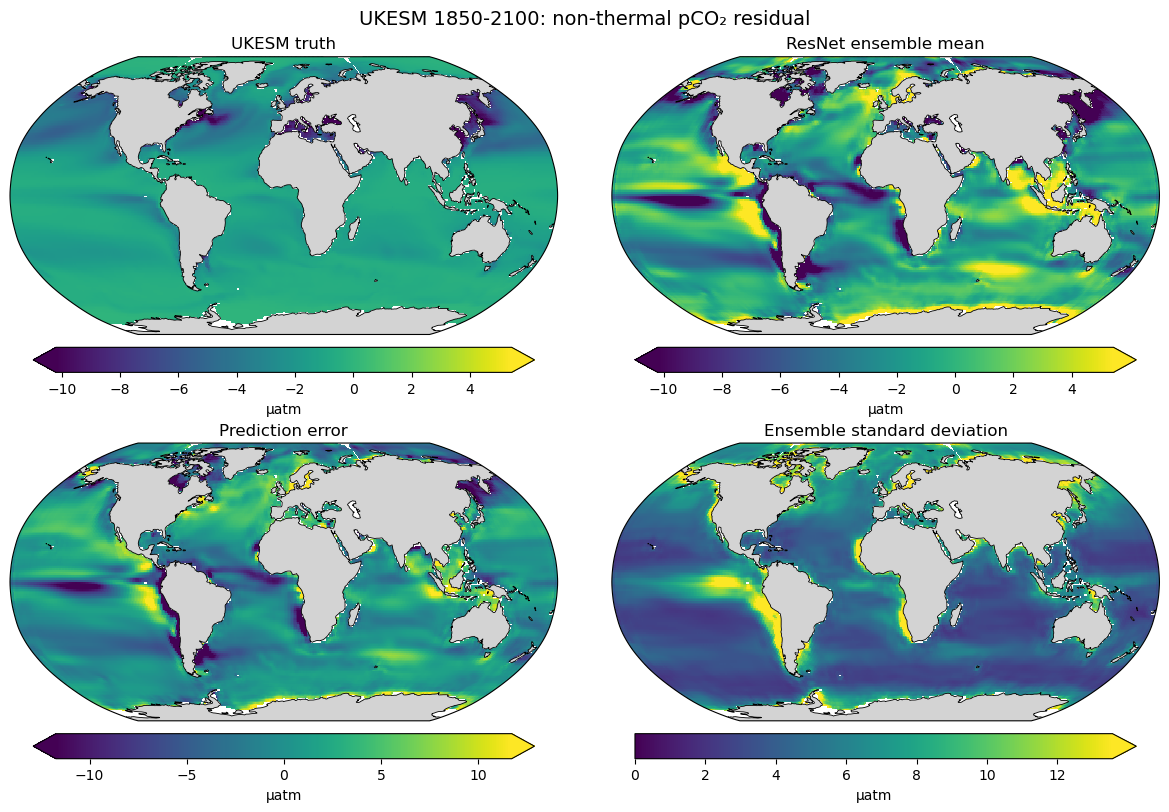

/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:9: RuntimeWarning: Mean of empty slice
  truth = np.nanmean(results[f"true_{target}"], axis=0)
/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:10: RuntimeWarning: Mean of empty slice
  pred = np.nanmean(results[f"pred_{target}"], axis=0)
/var/tmp/pbs.3928226.pbs-7/ipykernel_2882028/1218046267.py:12: RuntimeWarning: Mean of empty slice
  spread = np.nanmean(results[f"std_{target}"], axis=0)


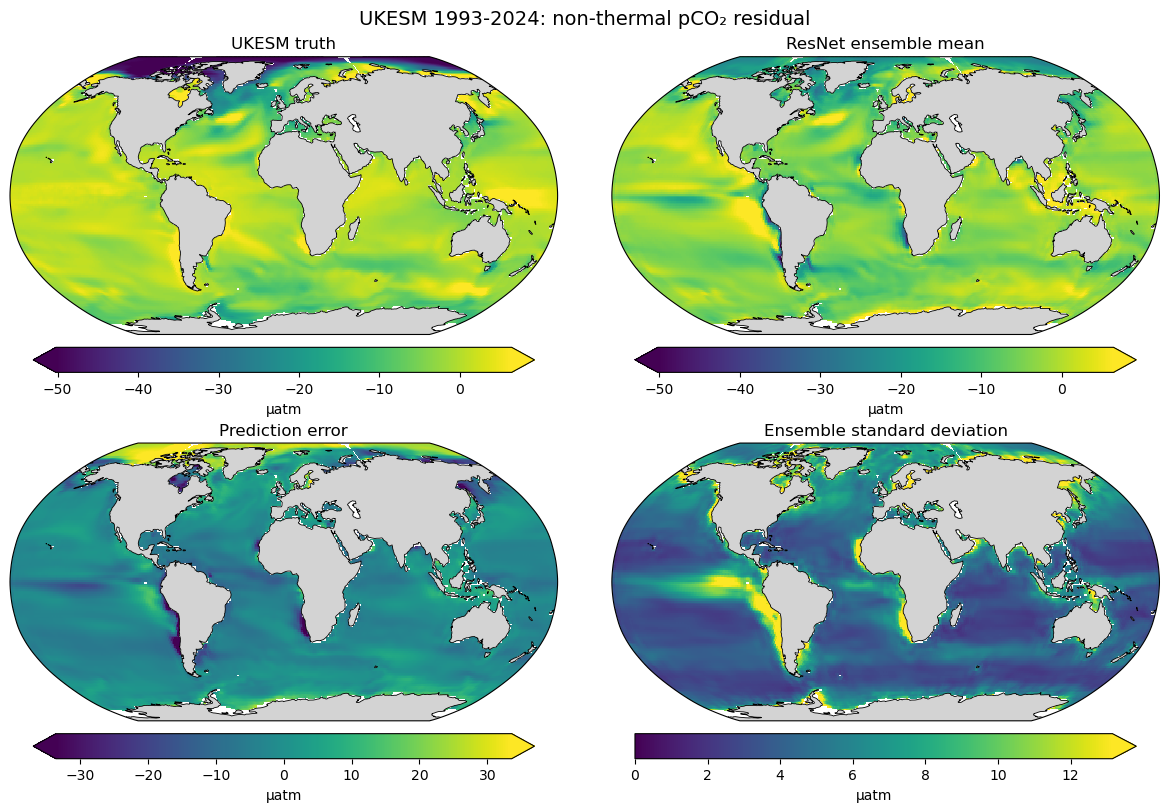

In [12]:
def plot_mean_maps(results, title, filename, target="resid"):
    """
    Plot time-mean truth, ensemble mean, prediction error
    and ensemble spread as a 2x2 Robinson projection figure.
    Colour limits are clipped at the 2nd and 98th percentiles
    for better spatial contrast.
    """

    truth = np.nanmean(results[f"true_{target}"], axis=0)
    pred = np.nanmean(results[f"pred_{target}"], axis=0)
    error = pred - truth
    spread = np.nanmean(results[f"std_{target}"], axis=0)

    lon = ds_ukesm.lon.values
    lat = ds_ukesm.lat.values

    # Colour limits

    # Shared limits for truth and prediction
    combined = np.concatenate([
        truth[np.isfinite(truth)],
        pred[np.isfinite(pred)],
    ])

    data_min, data_max = np.percentile(combined, [2, 98])

    # Symmetric scale for error
    error_abs = np.abs(error[np.isfinite(error)])
    error_max = np.percentile(error_abs, 98)

    # Scale for ensemble spread
    spread_max = np.percentile(
        spread[np.isfinite(spread)],
        98
    )

    fields = [truth, pred, error, spread]

    titles = [
        "UKESM truth",
        "ResNet ensemble mean",
        "Prediction error",
        "Ensemble standard deviation",
    ]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 8),
        subplot_kw={"projection": ccrs.Robinson()},
        constrained_layout=True,
    )

    # Colour limits
    vmins = [
        data_min,
        data_min,
        -error_max,
        0,
    ]

    vmaxs = [
        data_max,
        data_max,
        error_max,
        spread_max,
    ]

    # Colourbar extensions
    extends = [
        "both",
        "both",
        "both",
        "max",
    ]

    for ax, field, panel_title, vmin, vmax, extend in zip(
        axes.flat,
        fields,
        titles,
        vmins,
        vmaxs,
        extends,
    ):
        im = ax.pcolormesh(
            lon,
            lat,
            field,
            transform=ccrs.PlateCarree(),
            shading="auto",
            vmin=vmin,
            vmax=vmax,
            rasterized=True,
        )

        # Map features
        ax.add_feature(
            cfeature.LAND,
            facecolor="lightgray",
            edgecolor="none",
            zorder=2,
        )
        ax.coastlines(linewidth=0.6, zorder=3)
        ax.set_global()
        ax.set_title(panel_title)

        cbar = fig.colorbar(
            im,
            ax=ax,
            orientation="horizontal",
            pad=0.04,
            shrink=0.85,
            extend=extend,
        )

        cbar.set_label("µatm")

    fig.suptitle(title, fontsize=14)

    fig.savefig(
        os.path.join(FIGURES_DIR, filename),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_mean_maps(
    full_results,
    "UKESM 1850-2100: non-thermal pCO₂ residual",
    "resnet_ukesm_1850_2100_residual_ensemble.png",
    target="resid",
)

plot_mean_maps(
    recon_results,
    "UKESM 1993-2024: non-thermal pCO₂ residual",
    "resnet_ukesm_1993_2024_residual_ensemble.png",
    target="resid",
)

### Temporal: annual mean residual



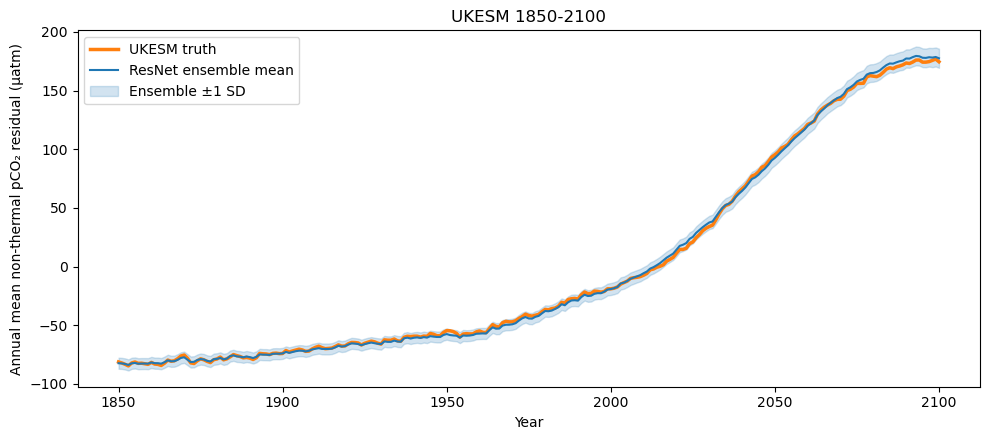

In [13]:
def annual_mean(values, times):
    years = np.array([t.year for t in times])
    unique_years = np.unique(years)
    out = np.array([np.nanmean(values[years == y]) for y in unique_years])
    return unique_years, out

times = full_results["time"]
years = np.array([t.year for t in times])

truth_monthly = np.nanmean(full_results["true_resid"], axis=(1, 2))
pred_monthly = np.nanmean(full_results["pred_resid"], axis=(1, 2))
std_monthly = np.nanmean(full_results["std_resid"], axis=(1, 2))

unique_years = np.unique(years)
truth_annual = np.array([np.nanmean(truth_monthly[years == y]) for y in unique_years])
pred_annual = np.array([np.nanmean(pred_monthly[years == y]) for y in unique_years])
std_annual = np.array([np.nanmean(std_monthly[years == y]) for y in unique_years])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    unique_years,
    truth_annual,
    color="tab:orange",
    linewidth=2.5,
    label="UKESM truth",
)
ax.plot(
    unique_years,
    pred_annual,
    color="tab:blue",
    linewidth=1.5,
    label="ResNet ensemble mean",
)
ax.fill_between(
    unique_years,
    pred_annual - std_annual,
    pred_annual + std_annual,
    color="tab:blue",
    alpha=0.2,
    label="Ensemble ±1 SD",
)

ax.set_xlabel("Year")
ax.set_ylabel("Annual mean non-thermal pCO₂ residual (µatm)")
ax.set_title("UKESM 1850-2100")
ax.legend()
fig.tight_layout()
fig.savefig(
    os.path.join(FIGURES_DIR, "resnet_ukesm_1850_2100_temporal.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Seasonal residual metrics

In [14]:
def temporal_metrics(results, grouping="season"):
    """
    Calculate metrics for either seasons or individual months.

    Parameters
    ----------
    results : dict
        Evaluation results containing time, true_resid and pred_resid.
    grouping : {"season", "month"}
        Whether to calculate seasonal or monthly metrics.
    """

    months = np.array([t.month for t in results["time"]])

    if grouping == "season":
        groups = {
            "DJF": [12, 1, 2],
            "MAM": [3, 4, 5],
            "JJA": [6, 7, 8],
            "SON": [9, 10, 11],
        }

    elif grouping == "month":
        groups = {
            "Jan": [1],
            "Feb": [2],
            "Mar": [3],
            "Apr": [4],
            "May": [5],
            "Jun": [6],
            "Jul": [7],
            "Aug": [8],
            "Sep": [9],
            "Oct": [10],
            "Nov": [11],
            "Dec": [12],
        }

    else:
        raise ValueError("grouping must be 'season' or 'month'")

    rows = []

    for group, group_months in groups.items():
        mask = np.isin(months, group_months)

        true = results["true_resid"][mask].ravel()
        pred = results["pred_resid"][mask].ravel()

        m = regression_metrics(true, pred)
        m["Group"] = group
        rows.append(m)

    return pd.DataFrame(rows)[
        ["Group", "N", "MAE", "RMSE", "Corr", "Bias"]
    ]


# Seasonal metrics
seasonal_df = temporal_metrics(full_results, grouping="season")
display(seasonal_df)

# Monthly metrics
monthly_df = temporal_metrics(full_results,  grouping="month")
display(monthly_df)

,Group,N,MAE,RMSE,Corr,Bias
0,DJF,31095888,11.279598,17.037968,0.982792,-1.439763
1,MAM,31095888,10.733809,18.613390,0.979817,-2.920557
2,JJA,31095888,11.302594,17.313944,0.982546,0.928194
3,SON,31095888,10.620559,16.243275,0.984813,3.373529


,Group,N,MAE,RMSE,Corr,Bias
0,Jan,10365296,11.916298,17.513115,0.982095,-2.101296
1,Feb,10365296,11.948654,18.280447,0.981220,-2.503558
2,Mar,10365296,10.984706,18.684183,0.980238,-2.352361
3,Apr,10365296,10.713819,19.183128,0.978765,-2.960698
4,May,10365296,10.502952,17.952288,0.980540,-3.448621
5,Jun,10365296,10.778060,16.564419,0.982792,-1.866399
6,Jul,10365296,11.110099,16.794092,0.983678,0.830754
7,Aug,10365296,12.019620,18.517467,0.982493,3.820226
8,Sep,10365296,11.666722,18.038479,0.982959,4.616982
9,Oct,10365296,10.369348,15.698509,0.985646,3.297001


## 4. Save tables

In [15]:
metrics_path = os.path.join(EVAL_SAVE_DIR, "resnet_ensemble_metrics.csv")
spread_path = os.path.join(EVAL_SAVE_DIR, "resnet_ensemble_spread.csv")
seasonal_path = os.path.join(EVAL_SAVE_DIR, "resnet_ensemble_seasonal_residual_metrics.csv")

metrics_df.to_csv(metrics_path, index=False)
spread_df.to_csv(spread_path, index=False)
seasonal_df.to_csv(seasonal_path, index=False)

print(metrics_path)
print(spread_path)
print(seasonal_path)

/rds/general/user/efs25/home/irp-efs25/data/evaluation/resnet_ensemble/resnet_ensemble_metrics.csv
/rds/general/user/efs25/home/irp-efs25/data/evaluation/resnet_ensemble/resnet_ensemble_spread.csv
/rds/general/user/efs25/home/irp-efs25/data/evaluation/resnet_ensemble/resnet_ensemble_seasonal_residual_metrics.csv
